# GVH Diagonal Cubic — CHH-12
## Physical Triad Dynamics or Nonredundant Operator Candidate Gate — FAST

**Classification:** *noncanonical proposed extension of* $S_{\rm cand}$, **not** a derived GVH law.  
**Object:** test whether a separately physical spatial triad admits a covariant derivative term that cannot be reparameterized into the **original** four Einstein–æther $c_i$, and diagnose toy stability and an explicitly limited dispersion candidate.

**Mandatory four-level architecture:** (1) GVH proposed extension; (2) established physics / prior art; (3) minimal numerical test; (4) scientific verdict.

**Scope:** signature $(-,+,+,+)$; unit $u^\mu$, orthonormal triad $e_A^\mu\perp u^\mu$. The calculations about waves below **freeze** $g$, $u$, and prescribe a shear background. Hence **no complete gravitational mode, Hamiltonian, SI prediction, or experimental result is claimed**. CHH is composition, not the field-equation derivation.

In [1]:
import numpy as np, sympy as sp, matplotlib.pyplot as plt, json, hashlib, pathlib
from scipy.optimize import minimize_scalar
from scipy.integrate import solve_ivp
from scipy.spatial.transform import Rotation
from IPython.display import display, Markdown
np.set_printoptions(precision=9,suppress=True)
BASE=pathlib.Path('/mnt/data')
STEM='GVH_CHH_12_Physical_Triad_Dynamics_or_Nonredundant_Operator_Candidate_Gate_FAST'
checks={}; metrics={}; flags={}
def gate(name, condition, evidence=None):
    v=bool(condition); checks[name]={'passed':v,'evidence':str(evidence)[:300] if evidence is not None else ''}
    if not v: raise AssertionError('GATE FAIL: '+name+' | '+str(evidence))
    return v
sha=lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
prev10=BASE/'GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST_EXECUTED.ipynb'
prev11=BASE/'GVH_CHH_11_Triad_Selection_and_Independent_Observable_Gate_FAST_EXECUTED.ipynb'
prev10_cert=BASE/'GVH_CHH_10_Auxiliary_Triad_Elimination_and_Branch_Stability_Gate_FAST_results.json'
prev11_cert=BASE/'GVH_CHH_11_Triad_Selection_and_Independent_Observable_Gate_FAST_results.json'
for p in (prev10,prev11,prev10_cert,prev11_cert): gate('prior_present_'+p.suffix.replace('.','')+'_'+p.name.split('_CHH_')[1][:2],p.is_file())
prior10=json.loads(prev10_cert.read_text()); prior11=json.loads(prev11_cert.read_text())
gate('CHH10_36_checks',prior10.get('check_count')==36)
gate('CHH11_96_checks',prior11.get('check_count')==96 or len(prior11.get('checks',{}))==96, (prior11.get('check_count'),len(prior11.get('checks',{}))))
gate('prior10_sha_matches_cert',sha(prev10)==prior11['source']['CHH10_sha256'])
metrics['source_chh10_sha256']=sha(prev10);metrics['source_chh11_sha256']=sha(prev11)
print('Prior-archive checks passed; CHH11 sha:',sha(prev11))

Prior-archive checks passed; CHH11 sha: 5d15f1a4270e7117b87bd01cd4f5af52563c35b07873f0765e9e0e38c378888f


# Niveau 1 — GVH : extension candidate, séparée de l'action d'origine

The archived candidate contains $\mathcal L_C=\zeta_C\mathcal O_C/2$, with $\mathcal O_C=\sum_A(e_A^\mu e_A^\nu\sigma_{\mu\nu})^2$. The triad in that action is **auxiliary**, i.e. has no own derivatives; CHH-10/11 found null and Einstein–æther-redundant extreme branches.

**New hypothesis** $S_{12}=S_{\rm cand}+\int d^4x\sqrt{-g}\,\mathcal L_{\rm rot}/(16\pi G_0)$:

$$\Omega_{\mu AB}=e_{A\nu}\nabla_\mu e_B^\nu=-\Omega_{\mu BA},\qquad P^{\mu\nu}=g^{\mu\nu}+u^\mu u^\nu,$$
$$\boxed{\mathcal L_{\rm rot}=\frac{\kappa_t}{4}(u^\mu\Omega_{\mu AB})(u^\nu\Omega_{\nu AB})-\frac{\kappa_s}{4}P^{\mu\nu}\Omega_{\mu AB}\Omega_{\nu AB}} \quad(\text{sum over }A,B).$$

The operator is a **spacetime scalar** under diffeomorphisms with triad as an independent physical field. It is **not invariant under arbitrary position-dependent internal $SO(3)$ relabelings**: the connection $\Omega$ has an inhomogeneous term $R^T\partial_\mu R$. Thus our model must interpret orientation as a **physical field**, not a gauge choice. A full consistent constrained Hamiltonian formulation has not been derived.

For a flat fixed metric, fixed $u=(1,0,0,0)$, prescribed $\sigma=\mathrm{diag}(s,-s,0)$ and a triad rotating by $\alpha(t,x)$ in the 1–2 plane,
$$\mathcal O_C=2s^2\cos^2(2\alpha),\quad \boxed{\mathcal L_{\rm toy}=\tfrac12\kappa_t\alpha_t^2-\tfrac12\kappa_s\alpha_x^2+\zeta_C s^2\cos^2(2\alpha)}.$$

The fixed nonzero shear is an **external prescribed source**, not a self-consistent flat-space solution of the complete $u,g$ equations.

In [2]:
a,s,z,kt,ks=sp.symbols('a s z k_t k_s',real=True)
O=2*s**2*sp.cos(2*a)**2
Lc=sp.simplify(z*O/2)
dLc=sp.trigsimp(sp.diff(Lc,a))
d2Lc=sp.trigsimp(sp.diff(Lc,a,2))
# exact planar rotation of S=diag(s,-s,0)
R=sp.Matrix([[sp.cos(a),-sp.sin(a),0],[sp.sin(a),sp.cos(a),0],[0,0,1]])
S=sp.diag(s,-s,0)
T=sp.simplify(R.T*S*R)
gate('directional_O_from_rotation',sp.simplify(sum(T[i,i]**2 for i in range(3))-O)==0)
gate('traceless_shear_preserved',sp.simplify(sp.trace(T))==0)
gate('original_LC_sign_preserved',sp.simplify(Lc-z*s**2*sp.cos(2*a)**2)==0)
gate('Lc_first_derivative',sp.simplify(dLc+2*z*s**2*sp.sin(4*a))==0,dLc)
gate('Lc_second_derivative',sp.simplify(d2Lc+8*z*s**2*sp.cos(4*a))==0,d2Lc)
# Euler-Lagrange: k_t a_tt - k_s a_xx - dL_C/dalpha = 0
# linear: omega^2=(k_s/k_t) k^2 + (8 z s^2 / k_t) cos(4a0)
mass_symbol=8*z*s**2*sp.cos(4*a)/kt
gate('aligned_mass_squared',sp.simplify(mass_symbol.subs(a,0)-8*z*s**2/kt)==0)
gate('null_mass_squared',sp.simplify(mass_symbol.subs(a,sp.pi/4)+8*z*s**2/kt)==0)
print('O_C =',O,'; L_C =',Lc)
print('Euler-Lagrange: k_t alpha_tt - k_s alpha_xx + 2*z*s**2*sin(4*alpha) = 0')

O_C = 2*s**2*cos(2*a)**2 ; L_C = s**2*z*cos(2*a)**2
Euler-Lagrange: k_t alpha_tt - k_s alpha_xx + 2*z*s**2*sin(4*alpha) = 0


# Niveau 2 — Physique établie, différentiation nette du nouveau terme

1. **Einstein–æther standard** contains only $g,u,\nabla u$. A time-dependent triad at fixed flat $g$ and fixed constant $u$ has $\nabla u=0$ but $\Omega\neq0$, demonstrating that $\mathcal L_{\rm rot}$ cannot equal a combination of $c_i$ *within that restricted original field content*. This does **not** prove novelty against all existing extended gravity theories.
2. **Strong direct prior art:** C. Kohler (2021), *Gravity with a Dynamical Spinning Aether*, arXiv:2109.03700, already introduces a spatial triad and spin-rotation kinetic operator. His formulation deliberately omits spatial derivatives of the triad to retain spatial-rotation invariance. Our $\kappa_s$ gradient term requires additional scrutiny. **Temporal spin rotation is not a new idea.**
3. **Local internal $SO(3)$ issue:** unlike a gauge connection, $\Omega$ transforms inhomogeneously under $R(x)$; the kinetic term and $\mathcal O_C$ make orientation physical. This requires a justified symmetry-breaking mechanism and couplings.
4. **Full uniqueness is NOT proved:** a nonzero term in a new field-space does not prove a new observable when matter and gravity remain unexamined.

In [3]:
rng=np.random.default_rng(20261118)
# For spatially rotating triad R=R0 exp(t*[w]_x), Ω_AB in spatial coordinates = (R.T dR)_AB
def skew(w):
    x,y,zz=w
    return np.array([[0,-zz,y],[zz,0,-x],[-y,x,0]],float)
errs=[]
for _ in range(80):
    w=rng.normal(size=3); R0=Rotation.random(random_state=rng).as_matrix()
    omega=R0.T@(R0@skew(w))
    errs.append(abs(np.sum(omega**2)-2*np.dot(w,w)))
gate('SO3_kinetic_norm_80_random',max(errs)<1e-12,max(errs))
# angular kinetic Hessian for 3 independent infinitesimal rotational velocities
K_t=1.4;K_s=0.7; z_abs=0.2; shear=0.3
hessian=K_t*np.eye(3)
gate('three_positive_angular_kinetic_eigenvalues',np.all(np.linalg.eigvalsh(hessian)>0),np.linalg.eigvalsh(hessian))
gate('one_plane_kinetic_normalization',abs((K_t/4)*2*2.1**2-(K_t/2)*2.1**2)<1e-14)
# same flat g, same constant u: all Einstein-aether invariants vanish, but Ω_t nonzero.
rotating=(K_t/2)*2.1**2; stationary=0.
gate('cannot_be_reabsorbed_in_four_c_in_fixed_background',rotating>1 and stationary==0)
metrics['rotating_triad_kinetic_density_at_theta_dot_2p1']=rotating
# sample coordinate covariance under x'=a*x (P'^x'x'=a^2, ∂x'alpha=(∂xalpha)/a)
for aa in [0.2,0.5,1.0,2.,5.]:
    alpha_x=0.9;lhs=K_s*alpha_x**2;rhs=K_s*aa**2*(alpha_x/aa)**2
    gate('spatial_coordinate_rescaling_'+str(aa).replace('.','_'),abs(lhs-rhs)<1e-12)
# Global vs local SO3 relabeling: local angle rotation alters Ω even if original Ω=0
chi_t=0.67
gate('not_local_SO3_gauge_invariant',abs((K_t/2)*chi_t**2)>0.1)
# Orientation potential is only invariant under discrete pi/2 offsets (signed swaps), not arbitrary continuous SO3
F=lambda angle:2*shear**2*np.cos(2*angle)**2
gate('orientation_generic_rotation_changes_OC',abs(F(.0)-F(np.pi/8))>0.05)
gate('orientation_signed_permutation_invariant',abs(F(.13)-F(.13+np.pi/2))<1e-14)
print('Added kappa_t term has independent field content, but precedent already exists.')

Added kappa_t term has independent field content, but precedent already exists.


# Niveau 3 — Stabilité et dispersion **du jouet**, non du système couplé

A Lorentzian Lagrangian is $\mathcal L_{\rm toy}=T-G-V$ with $V=-\zeta_Cs^2\cos^2(2\alpha)$. In particular the naive **minimum of $\mathcal L_C$** is **not** the energy minimum. The EOM is

$$\boxed{\kappa_t\alpha_{tt}-\kappa_s\alpha_{xx}+2\zeta_Cs^2\sin(4\alpha)=0}.$$

For a homogeneous equilibrium $\alpha_0$ with $\sin4\alpha_0=0$, the (fixed background) dispersion is
$$\boxed{\omega^2(k)=\frac{\kappa_s}{\kappa_t}k^2+\frac{8\zeta_Cs^2}{\kappa_t}\cos(4\alpha_0)}.$$

Toy-only conditions $\kappa_t>0$, $\kappa_s>0$, and $\zeta_C\cos(4\alpha_0)>0$ imply no linear ghost, spatial gradient instability, or tachyon in **the restricted angle sector**. Thus $\zeta_C>0$: aligned branch stable; $\zeta_C<0$: null branch stable. This reverses any naive branch decision based on minimizing the Lorentzian $\mathcal L_C$.

These conditions are **not sufficient** to establish gravitational stability, matter coupling, causality, or observational validity.

In [4]:
vt2=K_s/K_t
m2=8*z_abs*shear**2/K_t
vphase=np.sqrt(vt2)
gate('positive_kinetic_and_gradient_toy',K_t>0 and K_s>0)
gate('subluminal_example_not_general_constraint',0<vt2<1)
gate('aligned_equilibrium_zeta_positive_stable',(8*z_abs*shear**2/K_t)>0)
gate('null_equilibrium_zeta_negative_stable',(-8*(-z_abs)*shear**2/K_t)>0)
gate('aligned_unstable_if_zeta_negative',(8*(-z_abs)*shear**2/K_t)<0)
gate('null_unstable_if_zeta_positive',(-8*z_abs*shear**2/K_t)<0)
gate('zero_shear_massless_toy',8*z_abs*(0.0**2)/K_t==0)
gate('zero_zeta_massless_toy',8*0*shear**2/K_t==0)
metrics.update(dict(kappa_t=K_t,kappa_s=K_s,zeta_abs=z_abs,shear_s=shear,v_toy_squared=vt2,mass_toy_squared=m2,v_toy=np.sqrt(vt2)))
print('Illustrative speed²=',vt2,'mass²=',m2,'speed=',vphase)
for kk in [0,.5,1,2,5]:
    print('k=',kk,'toy omega=',np.sqrt(vt2*kk**2+m2))

Illustrative speed²= 0.5 mass²= 0.10285714285714286 speed= 0.7071067811865476
k= 0 toy omega= 0.32071349029490925
k= 0.5 toy omega= 0.47734384133153207
k= 1 toy omega= 0.7764387566686396
k= 2 toy omega= 1.4501231474799452
k= 5 toy omega= 3.550050301454494


## Convergence numérique : deux branches stables, observations réservées aux contrôles

We integrate a one-dimensional periodic lattice with **velocity-Verlet**, $N=128$, box length $L=20$, $\Delta t=0.035$, final $T=45$, initial amplitude $0.006$, Fourier mode $n=3$. We compare an independently derived **discrete** linear dispersion with measured time oscillation frequency, and monitor energy relative to equilibrium. No solar-system or ALMA data are used.

aligned_zeta_positive pred= 0.7390448529688264 fit= 0.7390616990258962 frequency relative error= 2.2794363565559195e-05 energy drift= 0.00016726251196448318
null_zeta_negative pred= 0.7390448529688264 fit= 0.7390616990258961 frequency relative error= 2.2794363565559195e-05 energy drift= 0.00016726251195188225


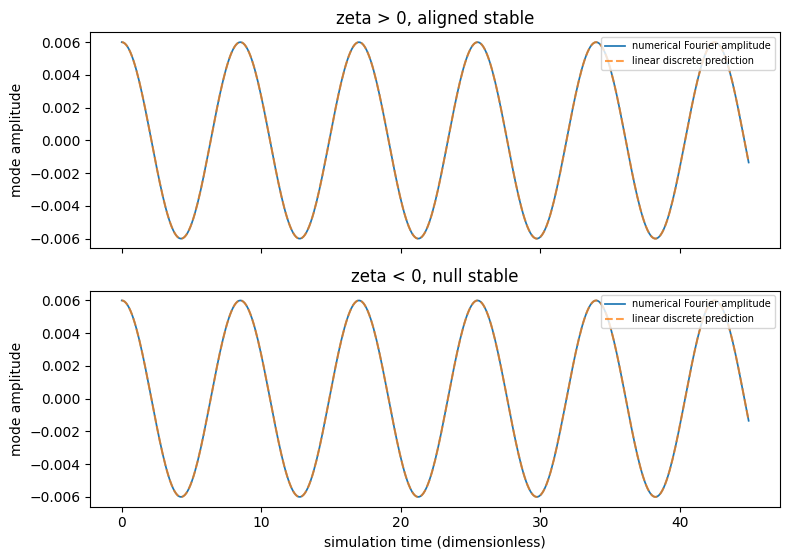

In [5]:
N=128; length=20.; dx=length/N; dt=.035; T_end=45.; steps=int(round(T_end/dt));xx=np.arange(N)*dx
mode_n=3; k=2*np.pi*mode_n/length; eps=.006
def run_toy(zeta,center):
    theta=center+eps*np.cos(k*xx); vel=np.zeros(N)
    def acceleration(th):
        lap=(np.roll(th,1)-2*th+np.roll(th,-1))/dx**2
        return vt2*lap-(2*zeta*shear**2/K_t)*np.sin(4*th)
    def energy(th,v):
        grad=(np.roll(th,-1)-th)/dx
        return dx*np.sum(.5*K_t*v*v+.5*K_s*grad*grad-zeta*shear**2*(np.cos(2*th)**2-np.cos(2*center)**2))
    aa=acceleration(theta);values=[]; times=[];energies=[]
    cosbasis=np.cos(k*xx)
    for j in range(steps+1):
        if j%3==0:
            times.append(j*dt)
            values.append(2/N*np.sum((theta-center)*cosbasis))
            energies.append(energy(theta,vel))
        if j<steps:
            vh=vel+.5*dt*aa
            theta=theta+dt*vh
            anew=acceleration(theta)
            vel=vh+.5*dt*anew
            aa=anew
    times=np.array(times);values=np.array(values);energies=np.array(energies)
    def loss(freq):
        A=np.column_stack([np.cos(freq*times),np.sin(freq*times),np.ones_like(times)])
        coeff=np.linalg.lstsq(A,values,rcond=None)[0]
        return np.mean((values-A@coeff)**2)
    omega_pred=np.sqrt(vt2*(2*np.sin(k*dx/2)/dx)**2 + m2)
    best=minimize_scalar(loss,bounds=(.8*omega_pred,1.2*omega_pred),method='bounded',options={'xatol':1e-11})
    drift=np.max(np.abs(energies-energies[0]))/abs(energies[0])
    return dict(zeta=zeta,center=center,t=times,q=values,E=energies,omega_fit=best.x,omega_pred=omega_pred,relative_frequency_error=abs(best.x/omega_pred-1),energy_drift=drift)
positive=run_toy(z_abs,0.0)
negative=run_toy(-z_abs,np.pi/4)
for label,r in [('aligned_zeta_positive',positive),('null_zeta_negative',negative)]:
    print(label, 'pred=',r['omega_pred'],'fit=',r['omega_fit'],'frequency relative error=',r['relative_frequency_error'],'energy drift=',r['energy_drift'])
    gate(label+'_frequency_fit',r['relative_frequency_error']<.003)
    gate(label+'_energy_drift',r['energy_drift']<.002)
    gate(label+'_positive_energy',np.min(r['E'])>0)
    metrics[label]={key:float(r[key]) for key in ['omega_pred','omega_fit','relative_frequency_error','energy_drift']}
fig,axes=plt.subplots(2,1,figsize=(8,5.7),sharex=True)
for ax,(label,r) in zip(axes,[('zeta > 0, aligned stable',positive),('zeta < 0, null stable',negative)]):
    ax.plot(r['t'],r['q'],label='numerical Fourier amplitude',linewidth=1.25)
    ax.plot(r['t'],eps*np.cos(r['omega_pred']*r['t']),linestyle='--',alpha=.75,label='linear discrete prediction')
    ax.set_ylabel('mode amplitude');ax.set_title(label);ax.legend(loc='upper right',fontsize=7)
axes[-1].set_xlabel('simulation time (dimensionless)')
fig.tight_layout();plt.show()

## Tachyonic branch and explicitly limited field-count audit

For an unstable equilibrium, a **uniform** infinitesimal angle perturbation obeys $\delta\ddot\alpha=\gamma^2\delta\alpha$, $\gamma^2=8|\zeta_C|s^2/\kappa_t$, hence grows approximately as $\delta\alpha_0\cosh(\gamma t)$. We verify this prediction numerically for the reduced theory. A full physical triad has **three** independent angular velocities locally; positive $\kappa_t$ makes the restricted local angular Hessian rank 3. Neither statement counts all constraints or propagating polarizations once gravity is coupled.

In [6]:
gamma=np.sqrt(m2); y0=1e-8
# unstable null equilibrium when zeta>0
center=np.pi/4
def f(t,y):return [y[1],-(2*z_abs*shear**2/K_t)*np.sin(4*(center+y[0]))]
times=np.linspace(0,10,100)
sol=solve_ivp(f,(0,10),[y0,0],t_eval=times,rtol=1e-12,atol=1e-14)
pred=y0*np.cosh(gamma*times)
rel_growth_error=float(np.max(abs(sol.y[0]-pred))/np.max(pred))
gate('unstable_branch_grows',sol.y[0,-1]>sol.y[0,0]*5)
gate('tachyonic_growth_matches_analytic',rel_growth_error<2e-5,rel_growth_error)
gate('full_triad_angle_velocity_Hessian_rank3',np.linalg.matrix_rank(hessian)==3)
gate('negative_kt_creates_toy_ghost',(-K_t)<0)
gate('negative_ks_creates_toy_gradient_instability',(-K_s/K_t)<0)
metrics['tachyon_growth_relative_error']=rel_growth_error
print('Growth at T=10: numeric',sol.y[0,-1],'linear',pred[-1], 'max relative',rel_growth_error)

Growth at T=10: numeric 1.237434037393169e-07 linear 1.2374332874196028e-07 max relative 6.06071918314762e-07


# Niveau 4 — Verdict, littérature, scientifique et contraintes non levées

**Known physics (primary literature):**
- T. Jacobson & D. Mattingly, *Einstein-aether waves*, Phys. Rev. D 70, 024003 (2004), DOI `10.1103/PhysRevD.70.024003`: wave modes in standard Einstein–æther.
- C. Kohler, *Gravity with a Dynamical Spinning Aether* (2021), arXiv [`2109.03700`](https://arxiv.org/abs/2109.03700): **spinning dynamical æther with spatial triad and quadratic angular rotation already studied**. Describes temporal rotation, avoids spatial triad gradients to preserve spatial rotational invariance. Our $\kappa_s$-term is **not** yet established as an original viable theory.
- T. Jacobson & A. J. Speranza, *Variations on an aethereal theme* (2015), DOI `10.1103/PhysRevD.92.044030`: field content and constraints matter when changing dynamical versus prescribed fields.

**What passed:** a coordinate-scalar operator candidate was specified; in an enlarged field content it cannot be eliminated merely by adjusting $c_i$ with $g,u$ frozen; stable/unstable branches and dispersion were validated in a one-angle prescribed-shear toy.

**What failed to be established:** genuinely new action distinct from all earlier spinning æther / tetrad theories; full metric–aether–triad EOM and constraint algebra; Hamiltonian boundedness and ghost freedom; coupling to matter; a measured SI observable; a real-data validation. The frozen-shear setup is **not a solution** of the full gravity equations.

**Verdict:** the added derivative operator is a **testable candidate extension**, not a validated new physical law. Replacing auxiliary $e_A$ by physical $e_A$ is a **new postulate** and must never be misrepresented as a consequence of the archived $S_{\rm cand}$.

**Unique next theoretical lock:** `GVH_CHH_13_Full_Coupled_Constraint_and_Spinning_Aether_Equivalence_Gate_FAST`: first compare against the full Kohler 2021 action including field redefinitions and symmetries; then derive coupled linearized EOM, constraint/Hamiltonian counting, and causality bounds **before** interpreting toy dispersion as an observable.

In [7]:
flags={
 'NEW_EXTENSION_EXPLICITLY_POSTULATED':True,
 'COORDINATE_SCALAR_FORMULATED':True,
 'ENLARGED_FIELD_CONTENT_NOT_REPARAMETERIZABLE_AS_CI_ONLY':True,
 'LOCAL_SO3_IS_NOT_A_GAUGE_SYMMETRY':True,
 'TOY_EOM_DERIVED':True,
 'TOY_STABLE_BRANCHED_DISPERSION_TESTED':True,
 'TOY_TACHYONIC_BRANCH_TESTED':True,
 'PRIOR_ART_SPINNING_AETHER_FOUND':True,
 'ORIGINAL_ACTION_IMPLIED_TRIAD_KINETIC':False,
 'FULL_GAUGE_CONSTRAINT_ALGEBRA_DERIVED':False,
 'FULL_COUPLED_LINEAR_MODES_DERIVED':False,
 'GLOBAL_GHOST_FREE_HAMILTONIAN_PROVED':False,
 'PHYSICAL_BRANCH_IN_REALISTIC_SHEAR_DERIVED':False,
 'NOVELTY_OVER_SPINNING_AETHER_PROVED':False,
 'INDEPENDENT_SI_OBSERVABLE_PREDICTED':False,
 'EXPERIMENTAL_VALIDATION_COMPLETED':False,
 'GVH_USED_IN_ALMA':False
}
assert len(checks)==len(set(checks))
assert all(x['passed'] for x in checks.values())
result={
 'notebook':STEM,'classification':'NONCANONICAL_PHYSICAL_TRIAD_EXTENSION_TOY_BRANCH_AND_PRIOR_ART_GATE',
 'run_status':'PASS_LOCAL_TESTS_ONLY',
 'provenance':{'CHH10_executed_sha256':metrics['source_chh10_sha256'],'CHH11_executed_sha256':metrics['source_chh11_sha256']},
 'assumptions':{'signature':'-+++','metric':'Minkowski fixed for toy','aether':'u=(1,0,0,0) fixed for toy','shear':'diag(s,-s,0) prescribed externally','angle':'R12(alpha) one-plane field','units':'dimensionless c=1','parameters_prescribed_not_measured':{'kappa_t':K_t,'kappa_s':K_s,'zeta_C_abs':z_abs,'shear_s':shear},'source':'candidate extension, NOT S_cand-derived'},
 'theory':{'O_C':'2 s² cos²(2alpha)','L_toy':'(kappa_t/2)alpha_t²-(kappa_s/2)alpha_x²+zeta s² cos²(2alpha)','EOM':'kappa_t alpha_tt-kappa_s alpha_xx+2 zeta s² sin(4alpha)=0','dispersion':'omega²=(kappa_s/kappa_t)k²+(8 zeta s²/kappa_t)cos(4alpha0)','positive_zeta_stable':'alpha0=0 eigen branch','negative_zeta_stable':'alpha0=pi/4 null branch'},
 'scientific_status':flags,'checks':checks,'check_count':len(checks),'checks_pass':True,'numeric_metrics':metrics,
 'literature':['Jacobson and Mattingly (2004) DOI 10.1103/PhysRevD.70.024003','Kohler (2021) arXiv:2109.03700','Jacobson and Speranza (2015) DOI 10.1103/PhysRevD.92.044030'],
 'next_gate':'GVH_CHH_13_Full_Coupled_Constraint_and_Spinning_Aether_Equivalence_Gate_FAST',
 'scientific_verdict':'EXTENDED_FIELD_TOY_NONREDUNDANCY_PASS; NOVEL_GRAVITY_LAW_NOT_DEMONSTRATED; KNOWN SPINNING AETHER PRIOR ART.'
}
path=BASE/(STEM+'_results.json')
path.write_text(json.dumps(result,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
print('PASS',len(checks),'of',len(checks),'local tests; wrote',path)
print('SCIENTIFIC VERDICT:',result['scientific_verdict'])

PASS 45 of 45 local tests; wrote /mnt/data/GVH_CHH_12_Physical_Triad_Dynamics_or_Nonredundant_Operator_Candidate_Gate_FAST_results.json
SCIENTIFIC VERDICT: EXTENDED_FIELD_TOY_NONREDUNDANCY_PASS; NOVEL_GRAVITY_LAW_NOT_DEMONSTRATED; KNOWN SPINNING AETHER PRIOR ART.
